# Capítulo 5 · Actividad: Titanic, ¿árbol o vecinos?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/riosinda/ml-course/blob/main/notebooks/exercises/chapter_05/04_actividad_titanic_arbol_knn.ipynb)

Compara un **árbol de decisión** y **KNN** para predecir si un pasajero del Titanic sobrevivió. Primero entiende los datos; el preprocesamiento lo decides tú. Los dos modelos tienen que evaluarse sobre la misma división de train y test, y con las mismas particiones de validación cruzada.

Cada fila es un pasajero. Para esta actividad usa las siguientes variables:

| Variable | Significado |
|---|---|
| `survived` | **Target**: `0` = no sobrevivió, `1` = sobrevivió |
| `pclass` | Clase del boleto: primera, segunda o tercera |
| `sex` | Sexo del pasajero |
| `age` | Edad en años |
| `sibsp` | Número de hermanos y cónyuges a bordo |
| `parch` | Número de padres e hijos a bordo |
| `fare` | Tarifa pagada |
| `embarked` | Puerto de embarque: `C`, `Q` o `S` |

Hay valores faltantes en `age` y `embarked`. Las clases de supervivencia no están balanceadas y las variables numéricas tienen escalas distintas.

**Usa únicamente las siete variables predictoras de la tabla.** El CSV contiene otras columnas: `alive`, por ejemplo, expresa la misma respuesta que `survived`. Incluirla entre las entradas sería una fuga de información: el modelo recibiría la respuesta que debe predecir. Tampoco incluyas `survived` entre las entradas.

Como mínimo, tu notebook debe incluir:

- La exploración de antes de modelar: forma de la tabla, nulos, balance de supervivencia, distribuciones y relación de las variables con la supervivencia.
- Una división estratificada de train y test y validación cruzada estratificada sobre train. Usa `random_state=42` en la división, en el árbol y al mezclar las particiones de validación.
- Un **árbol de decisión** y un **KNN**, los dos para clasificar. Decide cómo tratar los nulos, cómo codificar las variables categóricas y si estandarizas las numéricas: a KNN la escala le importa, al árbol no. Integra el preprocesamiento en un `Pipeline` para que se ajuste solo con los datos de entrenamiento de cada partición.
- La profundidad del árbol (y `min_samples_leaf`, si quieres) elegida con `GridSearchCV` sobre la validación cruzada.
- Para KNN, varios valores de `k`, incluyendo `k=1`, una **gráfica de la accuracy de train y de validación contra `k`** y el `k` que alcanza el máximo en validación. Distingue la accuracy sobre los mismos datos usados para entrenar de la obtenida en las particiones de validación. El test se usa una vez, al final, para evaluar ambos modelos elegidos, no para escoger hiperparámetros.
- Una **tabla** con los dos modelos: accuracy en validación cruzada (media y desviación estándar) y en prueba, y la matriz de confusión de cada uno en prueba. Compara también con una referencia sencilla: predecir siempre la clase mayoritaria de train.
- Tus **conclusiones**: con cuál te quedas y por qué. Explica la diferencia entre train y validación con `k=1`, cómo cambia al aumentar `k` y qué errores comete cada modelo al predecir supervivencia.

No hay una accuracy objetivo ni un ganador obligatorio. El objetivo es justificar la comparación con los resultados: `k=1` puede generalizar bien y la curva de validación no tiene por qué mejorar siempre al aumentar `k`. Si los modelos obtienen resultados muy parecidos, reconócelo en tus conclusiones.

1. **Copia esta notebook a `workspace/`** y trabaja sobre la copia.
2. Si todavía no tienes los datos: `uv run python scripts/download_data.py`


In [97]:
from pathlib import Path

from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,accuracy_score, classification_report, confusion_matrix, f1_score,
                             roc_auc_score, roc_curve,root_mean_squared_error)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (FunctionTransformer, MinMaxScaler, OneHotEncoder,
                                   OrdinalEncoder, StandardScaler)
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree

raiz = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
df = pd.read_csv(raiz / "data" / "titanic.csv")
df.head()


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## Exploracion

In [98]:
# Tu código aquí
df=df[["survived","pclass","sex","age","sibsp","parch","fare","embarked"]]
print("Filas y columnas:", df.shape)
print("Valores nulos:", df.isna().sum())
print("Valores por target:\n", df["survived"].value_counts())

Filas y columnas: (891, 8)
Valores nulos: survived      0
pclass        0
sex           0
age         177
sibsp         0
parch         0
fare          0
embarked      2
dtype: int64
Valores por target:
 survived
0    549
1    342
Name: count, dtype: int64


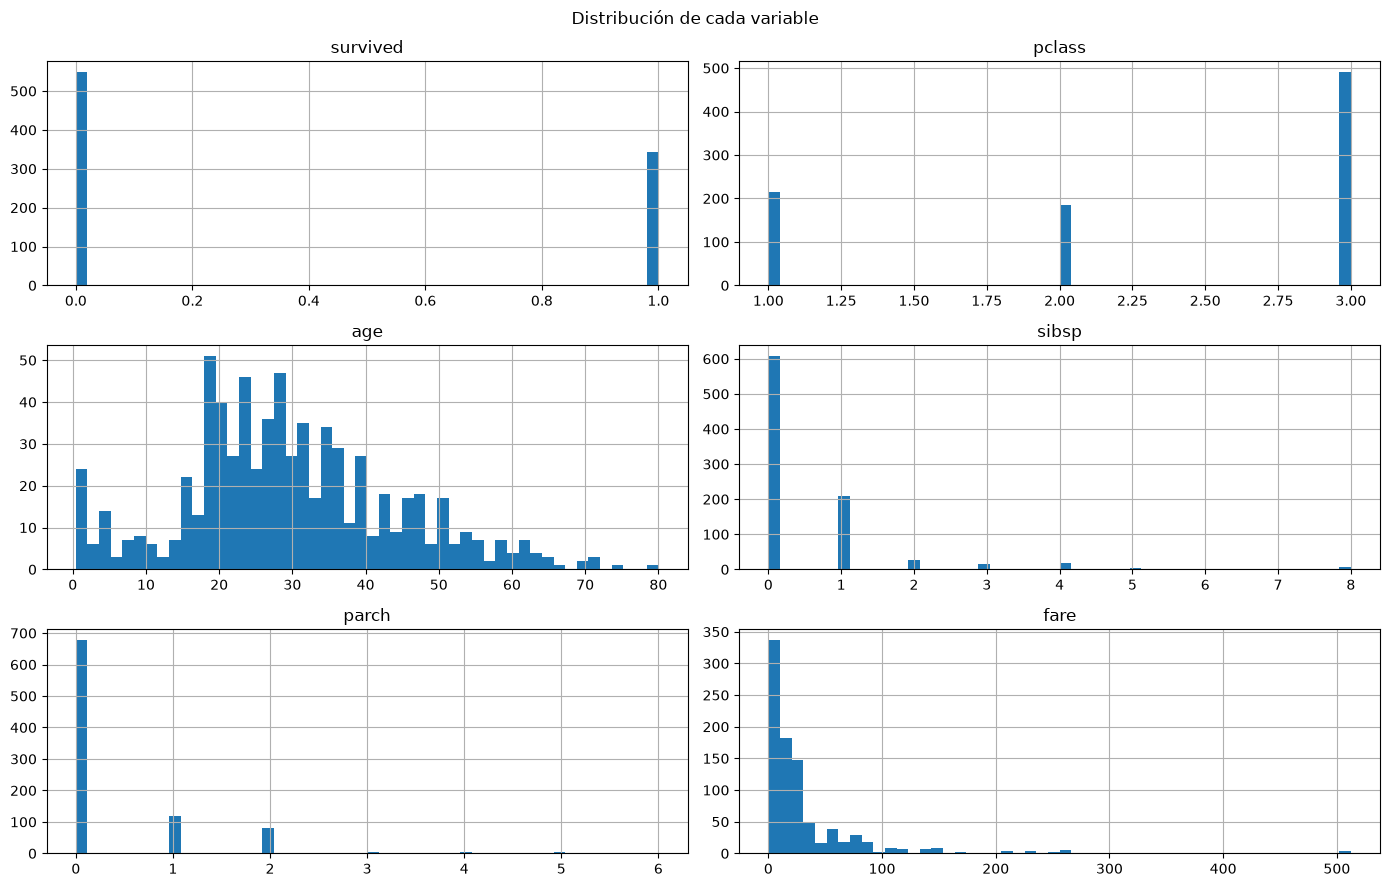

In [99]:
df.hist(bins=50, figsize=(14, 9))
plt.suptitle("Distribución de cada variable")
plt.tight_layout()
plt.show()

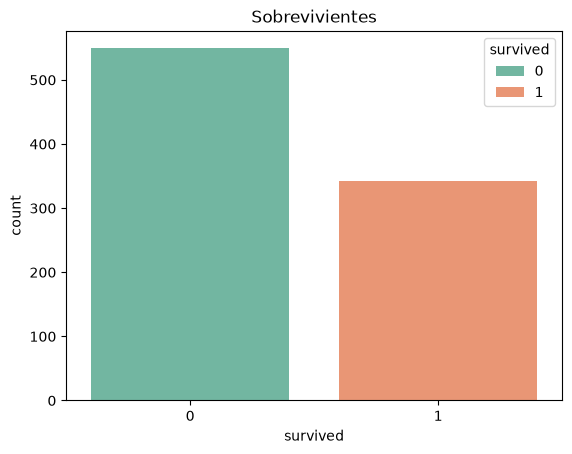

survived
0    549
1    342
Name: count, dtype: int64

In [100]:
ax = sns.countplot(data=df, x="survived", hue="survived",palette="Set2")
ax.set_title("Sobrevivientes")
plt.show()

df["survived"].value_counts()
# 0=no sobrevivio, 1=sobrevivio

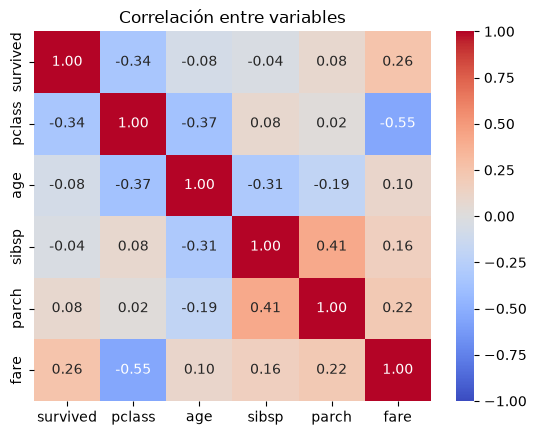

In [101]:
correlaciones = df.corr(numeric_only=True)

sns.heatmap(correlaciones, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlación entre variables")
plt.show()

## Preprocesamiento

In [102]:
#Relleno edades por medio de mediana y relleno con mediana
df["age"] = df["age"].fillna(df.groupby("pclass")["age"].transform("median"))


#Asignacion de ciudad de embarque por medio de moda 
moda = df["embarked"].mode()[0]    # mode() devuelve una Series: nos quedamos con el primer valor
df["embarked"] = df["embarked"].fillna(moda)
df["embarked"].value_counts()
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


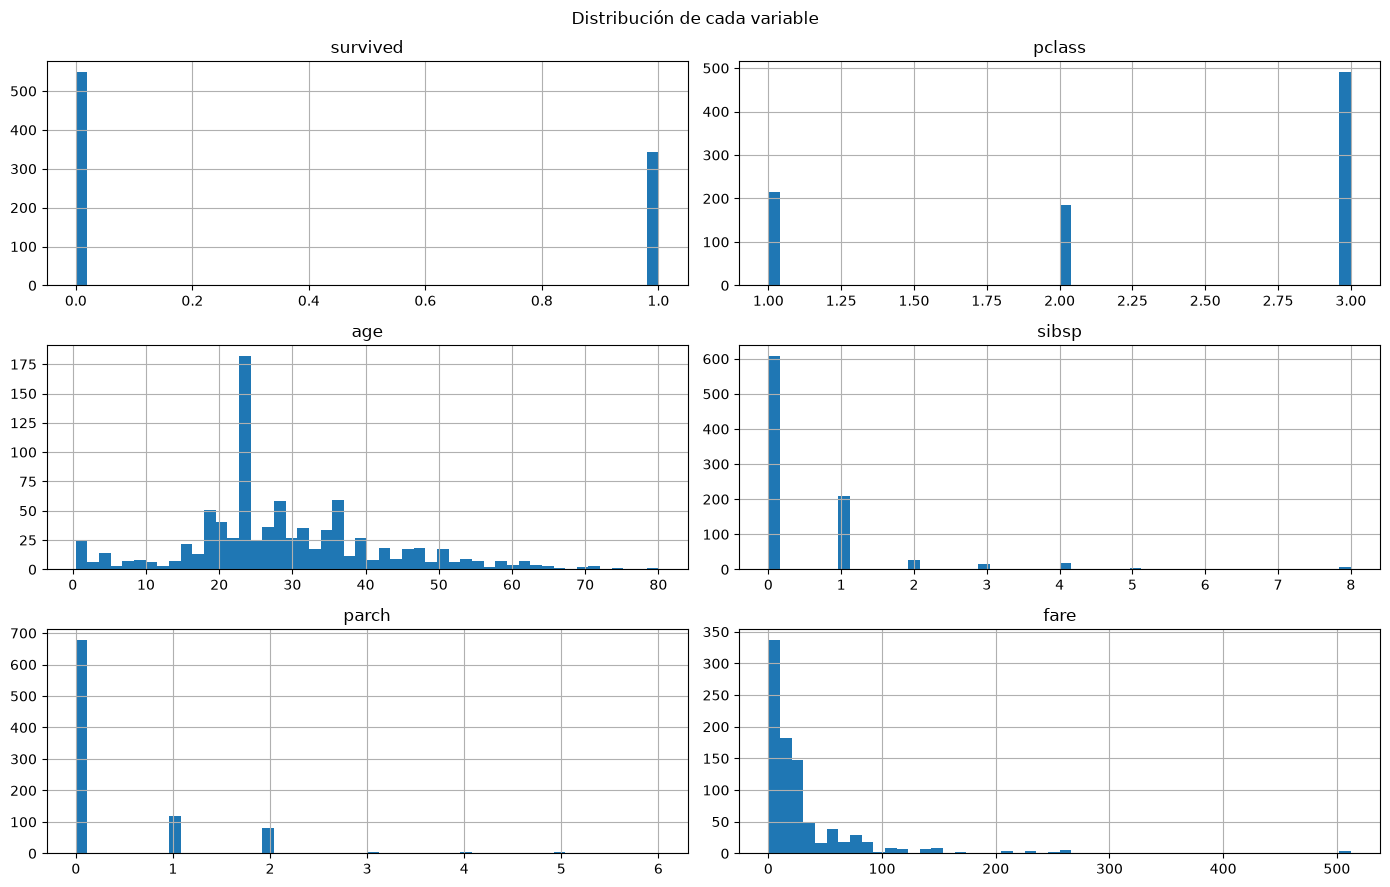

In [103]:
df.hist(bins=50, figsize=(14, 9))
plt.suptitle("Distribución de cada variable")
plt.tight_layout()
plt.show()

In [104]:
print("Filas y columnas:", df.shape)
df.info()

Filas y columnas: (891, 8)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   survived  891 non-null    int64  
 1   pclass    891 non-null    int64  
 2   sex       891 non-null    str    
 3   age       891 non-null    float64
 4   sibsp     891 non-null    int64  
 5   parch     891 non-null    int64  
 6   fare      891 non-null    float64
 7   embarked  891 non-null    str    
dtypes: float64(2), int64(4), str(2)
memory usage: 55.8 KB


In [105]:
df.describe().round(2)

,survived,pclass,age,sibsp,parch,fare
count,891.00,891.00,891.00,891.00,891.00,891.00
mean,0.38,2.31,29.07,0.52,0.38,32.20
std,0.49,0.84,13.24,1.10,0.81,49.69
min,0.00,1.00,0.42,0.00,0.00,0.00
25%,0.00,2.00,22.00,0.00,0.00,7.91
50%,0.00,3.00,26.00,0.00,0.00,14.45
75%,1.00,3.00,37.00,1.00,0.00,31.00
max,1.00,3.00,80.00,8.00,6.00,512.33


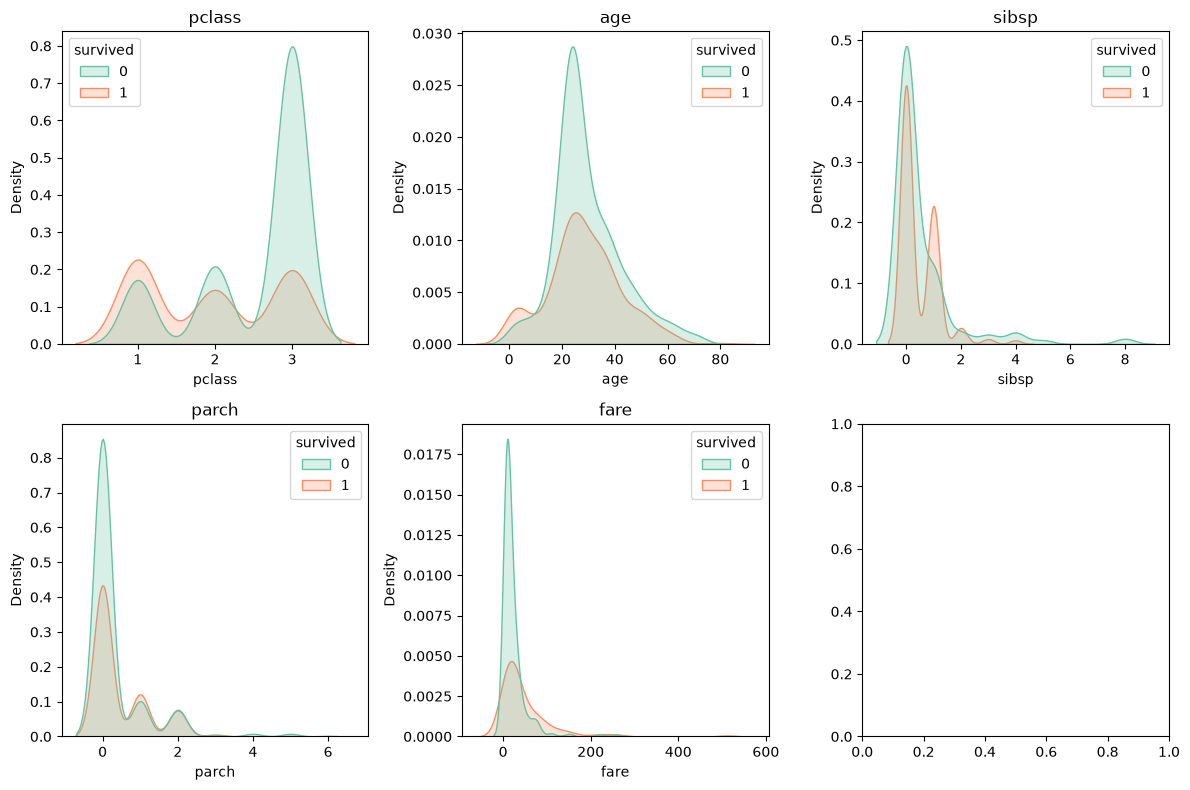

In [106]:
variables = ["pclass","age","sibsp","parch","fare"]

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for variable, ax in zip(variables, axes.flat):
    sns.kdeplot(data=df, x=variable, hue="survived", fill=True, palette="Set2", ax=ax)
    ax.set_title(variable)
plt.tight_layout()
plt.show()

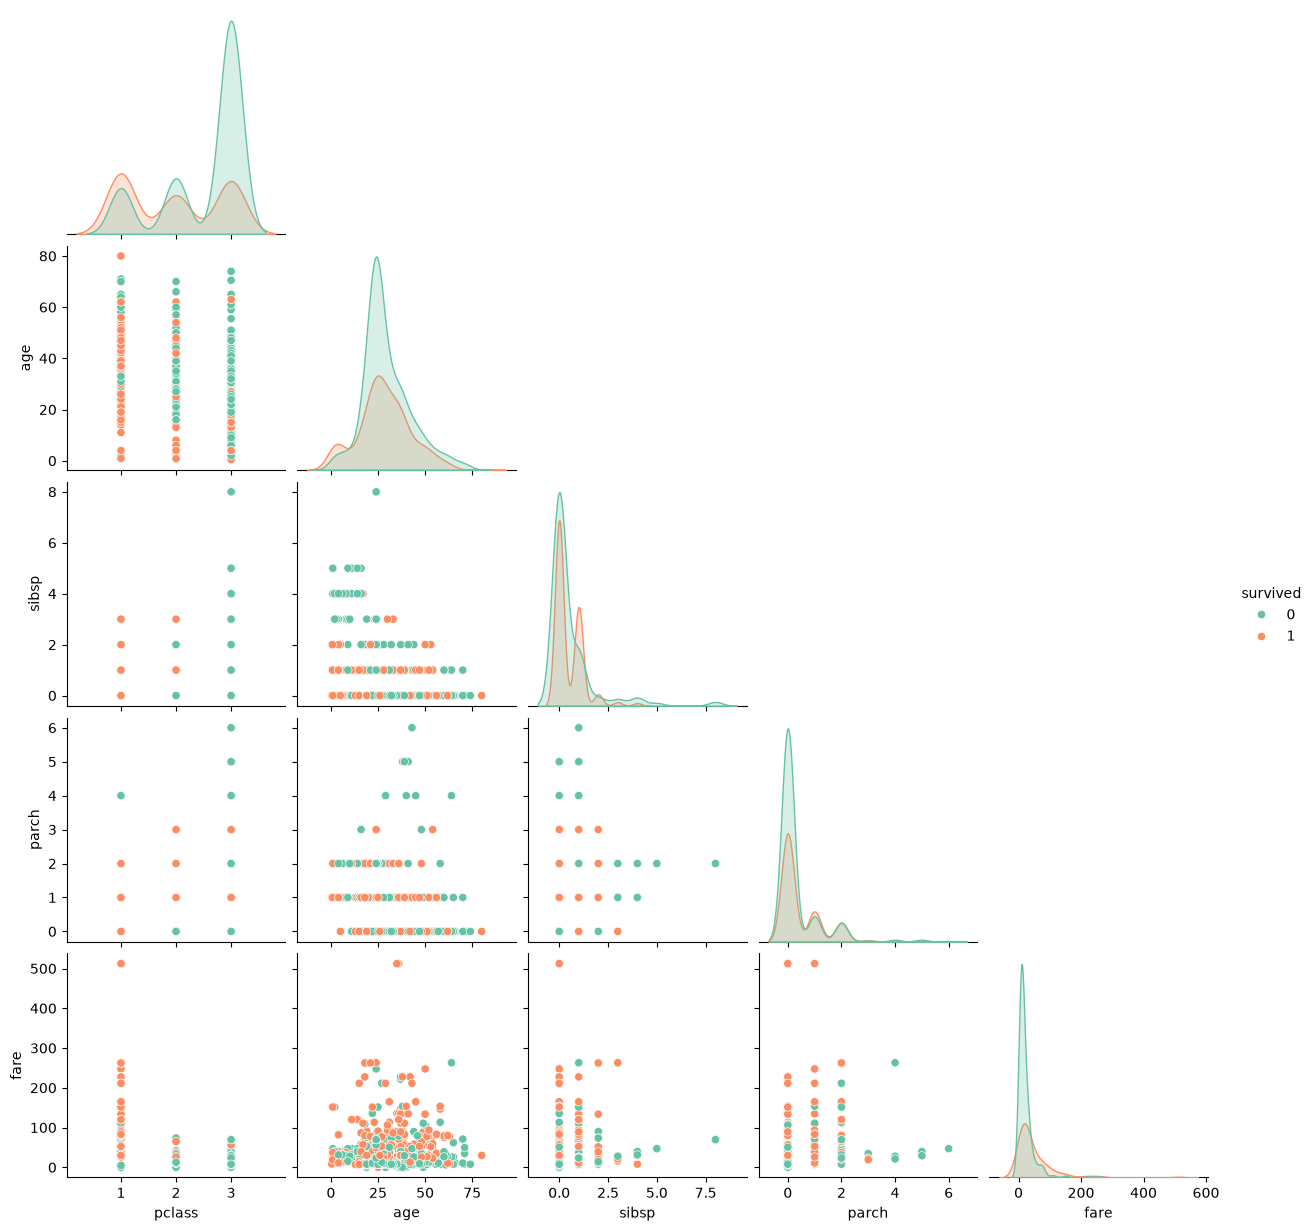

In [107]:
sns.pairplot(df, hue="survived", palette="Set2", corner=True)
plt.show()

### Pipeline

In [108]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


In [109]:
asimetricas = ["fare","age"]
numericas = ["sibsp","parch"]
nominales = ["sex","embarked","pclass"]
#ordinales = ["pclass"]

pipeline_asimetrico= Pipeline([
    ("log",FunctionTransformer(np.log1p,feature_names_out="one-to-one")),
    ("escalar",StandardScaler())
])

preprocesador = ColumnTransformer([
    ("num",StandardScaler(),numericas),
    ("asim",pipeline_asimetrico, asimetricas),
    ("nom",OneHotEncoder(handle_unknown="ignore",drop="if_binary",sparse_output=False),nominales)
    #("ord","passthrough",ordinales)
])
preprocesador

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('asim', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_

## Division estratificada

In [110]:
X=df.drop(columns=["survived"])
y=df["survived"]
X_train, X_test, y_train, y_test = train_test_split(X, y, 
                                                    test_size=0.2, stratify=y , random_state=42)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (712, 7) | Test: (179, 7)


In [111]:
X_train = preprocesador.fit_transform(X_train)
X_test=preprocesador.transform(X_test)

print("Train:", X_train.shape, "| Test:", X_test.shape)
pd.DataFrame({"train": y_train.value_counts(), "test": y_test.value_counts()})

Train: (712, 11) | Test: (179, 11)


,train,test
survived,,
0,439,110
1,273,69


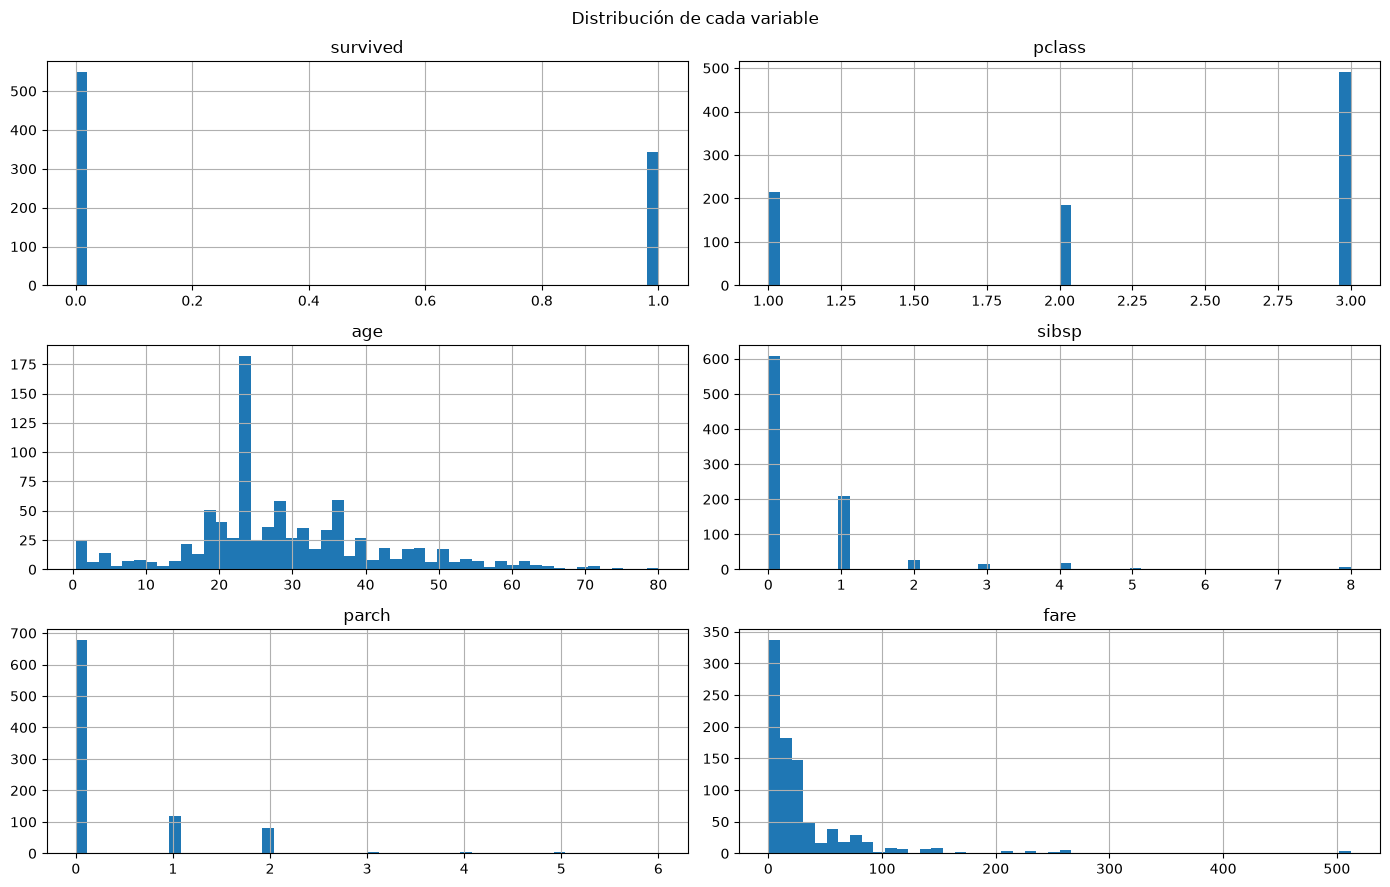

In [112]:
df.hist(bins=50, figsize=(14, 9))
plt.suptitle("Distribución de cada variable")
plt.tight_layout()
plt.show()

## Decission Tree

In [113]:
arbol = DecisionTreeClassifier(max_depth=None, ccp_alpha=0.0, random_state=42)
arbol.fit(X_train, y_train)

print(f"Accuracy en train: {arbol.score(X_train, y_train):.2f}")
print(f"Profundidad alcanzada: {arbol.get_depth()}")
print(f"Hojas: {arbol.get_n_leaves()}")

Accuracy en train: 0.98
Profundidad alcanzada: 24
Hojas: 152


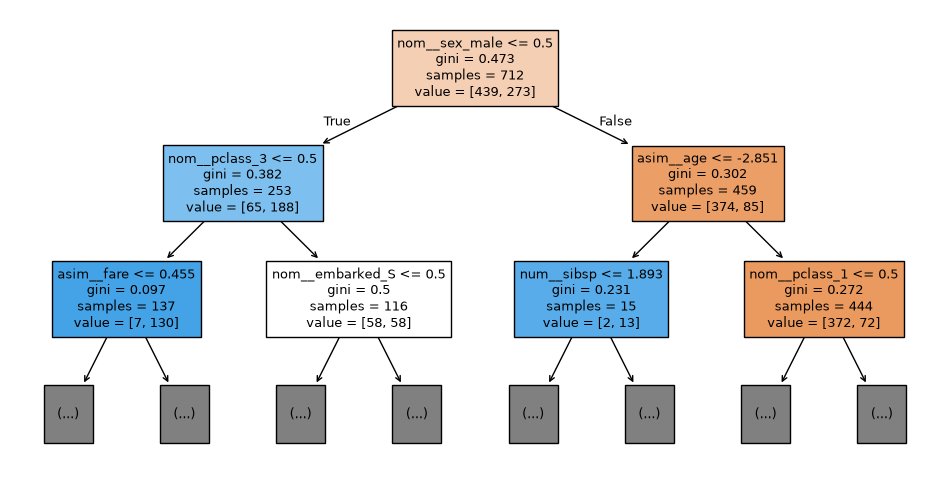

In [114]:
nombres = list(preprocesador.get_feature_names_out())

plt.figure(figsize=(12, 6))
plot_tree(
    arbol, max_depth=2, filled=True,
    feature_names=nombres,
    fontsize=9,
)
plt.show()

In [115]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

filas = []
for profundidad in [1, 2, 3, None]:
    modelo = DecisionTreeClassifier(max_depth=profundidad, random_state=42)
    modelo.fit(X_train, y_train)
    scores = cross_val_score(modelo, X_train, y_train, cv=cv, scoring="accuracy")
    filas.append({
        "max_depth": "sin límite" if profundidad is None else profundidad,
        "accuracy_train": modelo.score(X_train, y_train),
        "accuracy_validacion": scores.mean(),
    })

pd.DataFrame(filas).round(3)


,max_depth,accuracy_train,accuracy_validacion
0,1,0.789,0.789
1,2,0.805,0.791
2,3,0.833,0.805
3,sin límite,0.983,0.775


In [116]:
alphas = np.linspace(0.0, 0.1, 100)
busqueda_poda = GridSearchCV(
    DecisionTreeClassifier(max_depth=None, random_state=42),
    param_grid={"ccp_alpha": alphas},
    scoring="accuracy",
    cv=cv,
    return_train_score=True,
    refit=False,
    error_score="raise",
)
busqueda_poda.fit(X_train, y_train)

resultados_poda = pd.DataFrame(busqueda_poda.cv_results_)
curva_poda = pd.DataFrame({
    "alpha": resultados_poda["param_ccp_alpha"].astype(float),
    "train": resultados_poda["mean_train_score"],
    "validacion": resultados_poda["mean_test_score"],
    "std_validacion": resultados_poda["std_test_score"],
})

# Si empatan en validación, elegimos el alpha mayor: favorece un árbol más simple.
mejor_fila = curva_poda.sort_values(
    ["validacion", "alpha"], ascending=[False, False]
).iloc[0]
mejor_alpha = float(mejor_fila["alpha"])
print(f"Alpha elegido: {mejor_alpha:.3f}")
print(f"Accuracy de validación: {mejor_fila['validacion']:.3f}")
curva_poda.head()


Alpha elegido: 0.007
Accuracy de validación: 0.808


,alpha,train,validacion,std_validacion
0,0.00000,0.984550,0.775327,0.017149
1,0.00101,0.980686,0.775327,0.017149
2,0.00202,0.932227,0.790732,0.019525
3,0.00303,0.884835,0.794937,0.014398
4,0.00404,0.862706,0.804806,0.015868


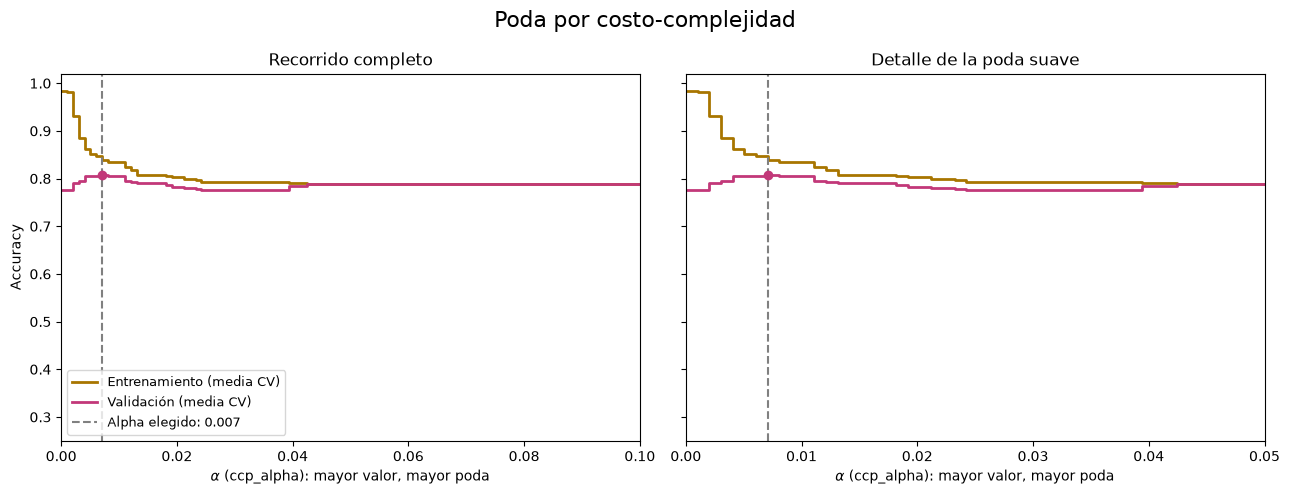

In [117]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax in axes:
    ax.step(curva_poda["alpha"], curva_poda["train"], where="post",
            label="Entrenamiento (media CV)", color="#a87500", linewidth=2)
    ax.step(curva_poda["alpha"], curva_poda["validacion"], where="post",
            label="Validación (media CV)", color="#c23879", linewidth=2)
    ax.axvline(mejor_alpha, color="gray", linestyle="--", label=f"Alpha elegido: {mejor_alpha:.3f}")
    ax.scatter([mejor_alpha], [mejor_fila["validacion"]], color="#c23879", zorder=3)
    ax.set_xlabel(r"$\alpha$ (ccp_alpha): mayor valor, mayor poda")
    ax.set_ylim(0.25, 1.02)
axes[0].set_xlim(0, alphas.max())
axes[0].set_ylabel("Accuracy")
axes[0].set_title("Recorrido completo")
axes[1].set_xlim(0, 0.05)
axes[1].set_title("Detalle de la poda suave")
axes[0].legend(loc="lower left", fontsize=9)
fig.suptitle("Poda por costo-complejidad", fontsize=16)
plt.tight_layout()
plt.show()


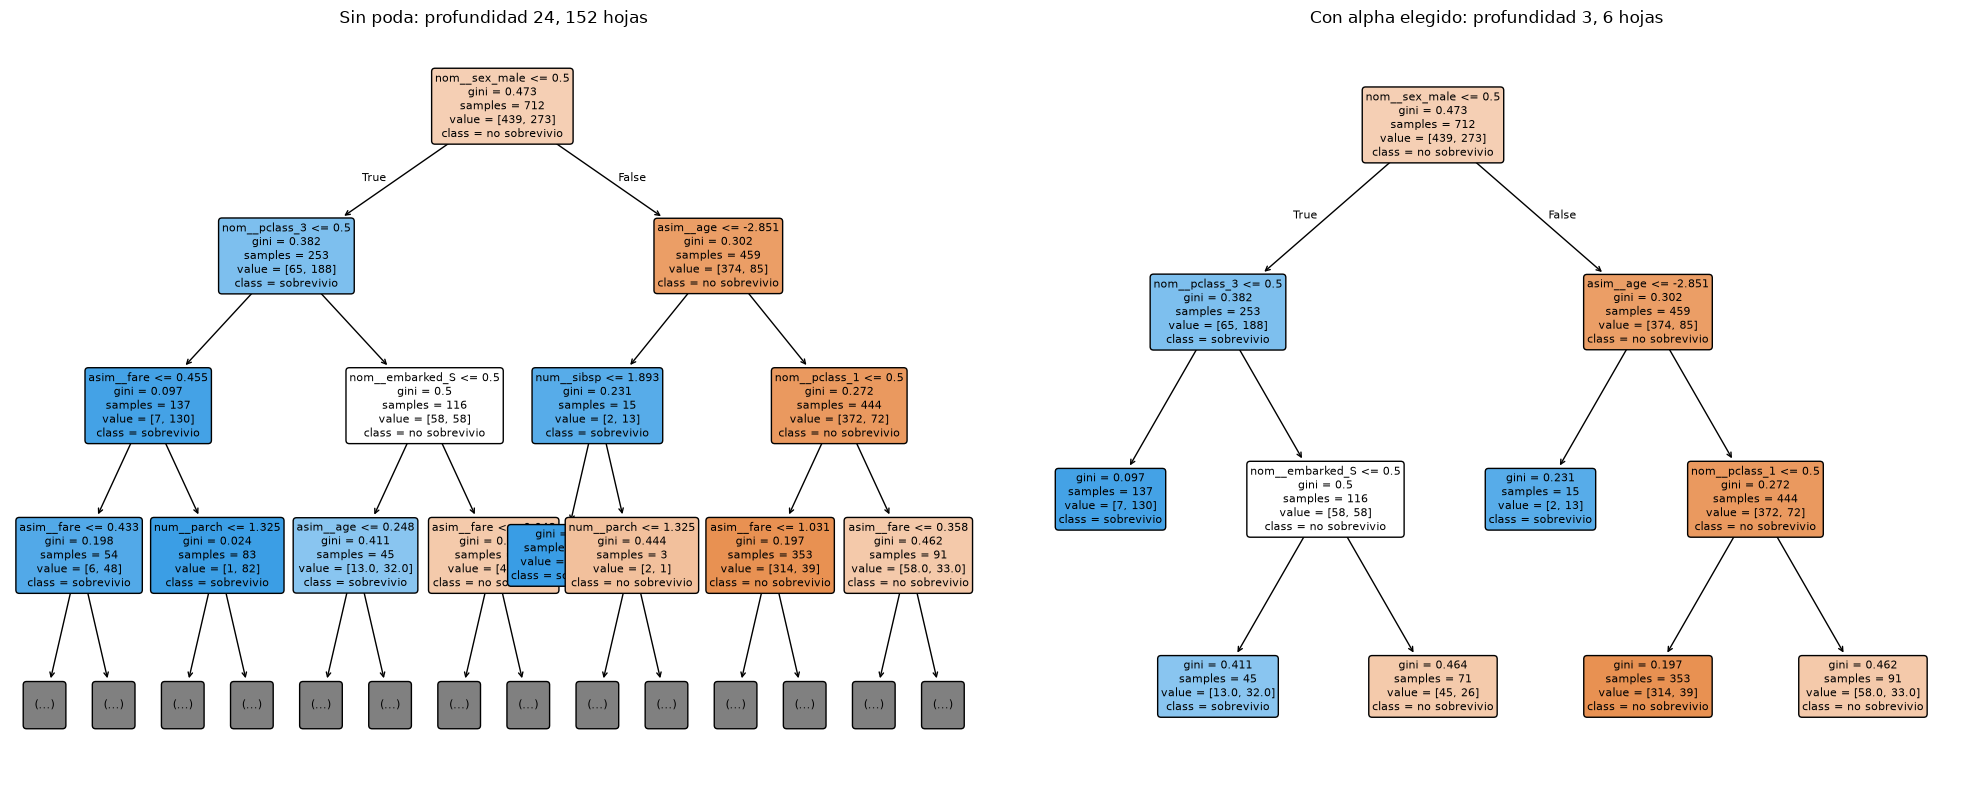

In [118]:
estado = ["no sobrevivio", "sobrevivio"]

fig, axes = plt.subplots(1, 2, figsize=(20, 8))
for ax, nombre, arbol_i in zip(
    axes, ["Sin poda", "Con alpha elegido"], [arbol, arbol_podado]
):
    plot_tree(
        arbol_i, max_depth=3, filled=True, rounded=True, fontsize=8,
        feature_names=nombres, class_names=estado, ax=ax,
    )
    ax.set_title(
        f"{nombre}: profundidad {arbol_i.get_depth()}, {arbol_i.get_n_leaves()} hojas"
    )
plt.tight_layout()
plt.show()

## K-NN